## Imports

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.style.use("ggplot")
pd.set_option('display.max_columns', 200)


## Data Set Info

In [2]:
data_path = Path("/Users/ssokolov/Documents/coding/FlightDelayPrediction/FlightData/flight_delays_2025_07.csv")
df = pd.read_csv(data_path)

#Information about the dataset July
display(df.head())
print("Rows and columns: ", df.shape)
print(df.columns.tolist())
df.info()
df.describe()



,Year,Quarter,Month,DayofMonth,DayOfWeek,FlightDate,Reporting_Airline,Flight_Number_Reporting_Airline,Origin,OriginCityName,OriginState,Dest,DestCityName,DestState,CRSDepTime,DepTime,DepDelay,DepDelayMinutes,DepDel15,TaxiOut,WheelsOff,WheelsOn,TaxiIn,CRSArrTime,ArrTime,ArrDelay,ArrDelayMinutes,ArrDel15,Cancelled,CancellationCode,Diverted,CRSElapsedTime,ActualElapsedTime,AirTime,Distance,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,2025,3,7,23,3,2025-07-23,AA,969,MIA,"Miami, FL",FL,CLT,"Charlotte, NC",NC,832,829.0,-3.0,0.0,0.0,26.0,855.0,1026.0,11.0,1042,1037.0,-5.0,0.0,0.0,0.0,NaN,0.0,130.0,128.0,91.0,650.0,NaN,NaN,NaN,NaN,NaN
1,2025,3,7,24,4,2025-07-24,AA,969,MIA,"Miami, FL",FL,CLT,"Charlotte, NC",NC,832,957.0,85.0,85.0,1.0,14.0,1011.0,1145.0,11.0,1042,1156.0,74.0,74.0,1.0,0.0,NaN,0.0,130.0,119.0,94.0,650.0,0.0,0.0,0.0,0.0,74.0
2,2025,3,7,25,5,2025-07-25,AA,969,MIA,"Miami, FL",FL,CLT,"Charlotte, NC",NC,832,828.0,-4.0,0.0,0.0,20.0,848.0,1017.0,7.0,1042,1024.0,-18.0,0.0,0.0,0.0,NaN,0.0,130.0,116.0,89.0,650.0,NaN,NaN,NaN,NaN,NaN
3,2025,3,7,26,6,2025-07-26,AA,969,MIA,"Miami, FL",FL,CLT,"Charlotte, NC",NC,832,827.0,-5.0,0.0,0.0,49.0,916.0,1043.0,9.0,1042,1052.0,10.0,10.0,0.0,0.0,NaN,0.0,130.0,145.0,87.0,650.0,NaN,NaN,NaN,NaN,NaN
4,2025,3,7,27,7,2025-07-27,AA,969,MIA,"Miami, FL",FL,CLT,"Charlotte, NC",NC,832,836.0,4.0,4.0,0.0,11.0,847.0,1021.0,8.0,1042,1029.0,-13.0,0.0,0.0,0.0,NaN,0.0,130.0,113.0,94.0,650.0,NaN,NaN,NaN,NaN,NaN


Rows and columns:  (631428, 40)
['Year', 'Quarter', 'Month', 'DayofMonth', 'DayOfWeek', 'FlightDate', 'Reporting_Airline', 'Flight_Number_Reporting_Airline', 'Origin', 'OriginCityName', 'OriginState', 'Dest', 'DestCityName', 'DestState', 'CRSDepTime', 'DepTime', 'DepDelay', 'DepDelayMinutes', 'DepDel15', 'TaxiOut', 'WheelsOff', 'WheelsOn', 'TaxiIn', 'CRSArrTime', 'ArrTime', 'ArrDelay', 'ArrDelayMinutes', 'ArrDel15', 'Cancelled', 'CancellationCode', 'Diverted', 'CRSElapsedTime', 'ActualElapsedTime', 'AirTime', 'Distance', 'CarrierDelay', 'WeatherDelay', 'NASDelay', 'SecurityDelay', 'LateAircraftDelay']
<class 'pandas.DataFrame'>
RangeIndex: 631428 entries, 0 to 631427
Data columns (total 40 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   Year                             631428 non-null  int64  
 1   Quarter                          631428 non-null  int64  
 2   Month                            6

,Year,Quarter,Month,DayofMonth,DayOfWeek,Flight_Number_Reporting_Airline,CRSDepTime,DepTime,DepDelay,DepDelayMinutes,DepDel15,TaxiOut,WheelsOff,WheelsOn,TaxiIn,CRSArrTime,ArrTime,ArrDelay,ArrDelayMinutes,ArrDel15,Cancelled,Diverted,CRSElapsedTime,ActualElapsedTime,AirTime,Distance,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
count,631428.0,631428.0,631428.0,631428.000000,631428.000000,631428.000000,631428.000000,616941.000000,616879.000000,616879.000000,616879.000000,616027.000000,616027.000000,615731.000000,615731.000000,631428.000000,615731.000000,612811.000000,612811.000000,612811.000000,631428.000000,631428.000000,631428.000000,612811.000000,612811.000000,631428.000000,177012.000000,177012.000000,177012.000000,177012.000000,177012.000000
mean,2025.0,3.0,7.0,16.152681,3.896839,2518.548965,1332.384418,1332.758902,21.512554,24.369165,0.286150,18.723798,1352.133848,1424.158478,8.993382,1482.353256,1425.214108,17.346069,24.551323,0.288853,0.024505,0.004979,148.913105,144.908102,117.221213,856.773176,25.297155,5.974335,16.864608,0.086265,33.221928
std,0.0,0.0,0.0,8.886865,1.952055,1623.405024,503.046152,532.424783,70.177479,69.078137,0.451961,11.399635,537.645553,575.567041,8.164364,535.078828,582.076982,72.063374,68.982002,0.453230,0.154610,0.070388,72.845332,73.733791,71.166497,610.417342,78.829476,39.896855,41.466763,2.892283,66.950938
min,2025.0,3.0,7.0,1.000000,1.000000,1.000000,4.000000,1.000000,-60.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,-83.000000,0.000000,0.000000,0.000000,0.000000,31.000000,16.000000,7.000000,31.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2025.0,3.0,7.0,9.000000,2.000000,1219.000000,902.000000,858.000000,-5.000000,0.000000,0.000000,12.000000,913.000000,1010.000000,5.000000,1050.000000,1013.000000,-13.000000,0.000000,0.000000,0.000000,0.000000,95.000000,91.000000,64.000000,406.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2025.0,3.0,7.0,16.000000,4.000000,2266.000000,1325.000000,1323.000000,-1.000000,0.000000,0.000000,16.000000,1334.000000,1438.000000,7.000000,1513.000000,1440.000000,-3.000000,0.000000,0.000000,0.000000,0.000000,132.000000,128.000000,100.000000,696.000000,3.000000,0.000000,0.000000,0.000000,7.000000
75%,2025.0,3.0,7.0,24.000000,6.000000,3631.000000,1745.000000,1800.000000,20.000000,20.000000,1.000000,21.000000,1815.000000,1914.000000,10.000000,1929.000000,1918.000000,20.000000,20.000000,1.000000,0.000000,0.000000,180.000000,177.000000,147.000000,1090.000000,21.000000,0.000000,18.000000,0.000000,40.000000
max,2025.0,3.0,7.0,31.000000,7.000000,9911.000000,2400.000000,2400.000000,2560.000000,2560.000000,1.000000,379.000000,2400.000000,2400.000000,380.000000,2359.000000,2400.000000,2557.000000,2557.000000,1.000000,1.000000,1.000000,665.000000,720.000000,644.000000,5095.000000,2557.000000,1817.000000,1387.000000,534.000000,2188.000000


## Missing values handling

In [3]:
#Inspecting the Dataset
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100,
}).sort_values("missing_percent", ascending=False)

display(missing_summary)
print("Exact duplicate rows:", df.duplicated().sum())

,missing_count,missing_percent
CancellationCode,615955,97.549523
LateAircraftDelay,454416,71.966400
SecurityDelay,454416,71.966400
NASDelay,454416,71.966400
WeatherDelay,454416,71.966400
CarrierDelay,454416,71.966400
AirTime,18617,2.948396
ActualElapsedTime,18617,2.948396
ArrDel15,18617,2.948396
ArrDelayMinutes,18617,2.948396


Exact duplicate rows: 0


In [4]:
display(df["Cancelled"].value_counts(dropna=False))
display(df["Diverted"].value_counts(dropna=False))
display(df["ArrDelay"].describe())

Cancelled
0.0    615955
1.0     15473
Name: count, dtype: int64

Diverted
0.0    628284
1.0      3144
Name: count, dtype: int64

count    612811.000000
mean         17.346069
std          72.063374
min         -83.000000
25%         -13.000000
50%          -3.000000
75%          20.000000
max        2557.000000
Name: ArrDelay, dtype: float64

## Dates preparation

In [5]:
#Dates preparation 
df["FlightDate"] = pd.to_datetime(
    df["FlightDate"],
    errors='coerce'
)
df["Month"] = df["FlightDate"].dt.month
df["weekday"] = df["FlightDate"].dt.dayofweek

completed = df.loc[
    df["Cancelled"].eq(0)
    & df["Diverted"].eq(0)
    & df["ArrDelay"].notna()
].copy()
completed["is_delayed"] = completed["ArrDelay"].ge(15)
completed["positive_arrival_delay"] = completed["ArrDelay"].clip(lower=0)
completed["departure_hour"] = (
    pd.to_numeric(completed["CRSDepTime"], errors = "coerce") // 100
) % 24
completed["weekday"] = completed["FlightDate"].dt.day_name()
display(completed.head())


,Year,Quarter,Month,DayofMonth,DayOfWeek,FlightDate,Reporting_Airline,Flight_Number_Reporting_Airline,Origin,OriginCityName,OriginState,Dest,DestCityName,DestState,CRSDepTime,DepTime,DepDelay,DepDelayMinutes,DepDel15,TaxiOut,WheelsOff,WheelsOn,TaxiIn,CRSArrTime,ArrTime,ArrDelay,ArrDelayMinutes,ArrDel15,Cancelled,CancellationCode,Diverted,CRSElapsedTime,ActualElapsedTime,AirTime,Distance,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay,weekday,is_delayed,positive_arrival_delay,departure_hour
0,2025,3,7,23,3,2025-07-23,AA,969,MIA,"Miami, FL",FL,CLT,"Charlotte, NC",NC,832,829.0,-3.0,0.0,0.0,26.0,855.0,1026.0,11.0,1042,1037.0,-5.0,0.0,0.0,0.0,NaN,0.0,130.0,128.0,91.0,650.0,NaN,NaN,NaN,NaN,NaN,Wednesday,False,0.0,8
1,2025,3,7,24,4,2025-07-24,AA,969,MIA,"Miami, FL",FL,CLT,"Charlotte, NC",NC,832,957.0,85.0,85.0,1.0,14.0,1011.0,1145.0,11.0,1042,1156.0,74.0,74.0,1.0,0.0,NaN,0.0,130.0,119.0,94.0,650.0,0.0,0.0,0.0,0.0,74.0,Thursday,True,74.0,8
2,2025,3,7,25,5,2025-07-25,AA,969,MIA,"Miami, FL",FL,CLT,"Charlotte, NC",NC,832,828.0,-4.0,0.0,0.0,20.0,848.0,1017.0,7.0,1042,1024.0,-18.0,0.0,0.0,0.0,NaN,0.0,130.0,116.0,89.0,650.0,NaN,NaN,NaN,NaN,NaN,Friday,False,0.0,8
3,2025,3,7,26,6,2025-07-26,AA,969,MIA,"Miami, FL",FL,CLT,"Charlotte, NC",NC,832,827.0,-5.0,0.0,0.0,49.0,916.0,1043.0,9.0,1042,1052.0,10.0,10.0,0.0,0.0,NaN,0.0,130.0,145.0,87.0,650.0,NaN,NaN,NaN,NaN,NaN,Saturday,False,10.0,8
4,2025,3,7,27,7,2025-07-27,AA,969,MIA,"Miami, FL",FL,CLT,"Charlotte, NC",NC,832,836.0,4.0,4.0,0.0,11.0,847.0,1021.0,8.0,1042,1029.0,-13.0,0.0,0.0,0.0,NaN,0.0,130.0,113.0,94.0,650.0,NaN,NaN,NaN,NaN,NaN,Sunday,False,0.0,8


## Dataset Classification (remark)
We will use df for cancellation/diversion analysis and Completed for arrival-delay analysis


# Summary

In [6]:
summary = pd.Series({
    "Scheduled flights": len(df),
    "Eligible completed flights": len(completed),
    "Arrival delay rate (%)": completed["is_delayed"].mean() * 100,
    "Arrival delay >= 60 min (%)": completed["ArrDelay"].ge(60).mean() * 100,
    "Cancellation rate (%)": df["Cancelled"].mean() * 100,
    "Diversion rate (%)": df["Diverted"].mean() * 100,
    "Mean positive arrival delay (min)": completed["positive_arrival_delay"].mean(),
    "90th percentile positive arrival delay (min)": completed["positive_arrival_delay"].quantile(0.90),
})
display(summary.round(2))

Scheduled flights                               631428.00
Eligible completed flights                      612811.00
Arrival delay rate (%)                              28.89
Arrival delay >= 60 min (%)                         12.08
Cancellation rate (%)                                2.45
Diversion rate (%)                                   0.50
Mean positive arrival delay (min)                   24.55
90th percentile positive arrival delay (min)        72.00
dtype: float64

# Plotting and analysis

## Arrival delay severity

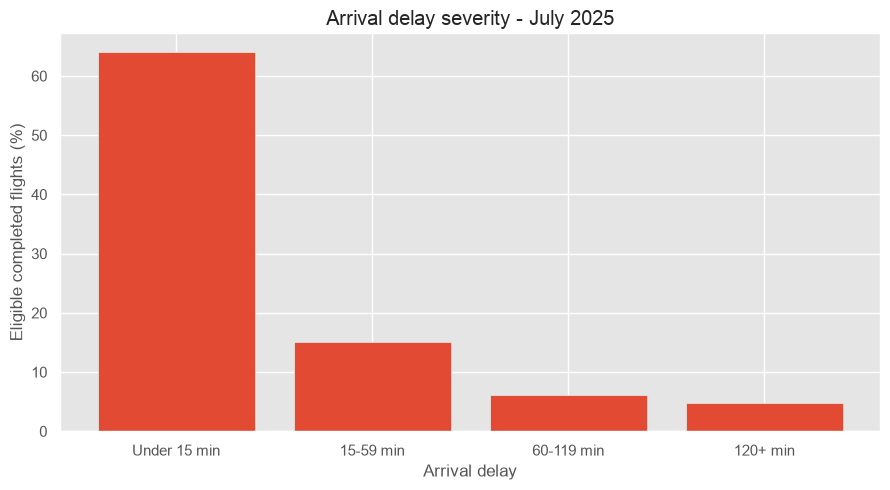

In [9]:
completed["delay_category"] = pd.cut(
    completed["ArrDelay"],
    bins=[-np.inf, 15 ,60, 120, np.inf],
    labels=["Under 15 min","15-59 min","60-119 min","120+ min"],
    right=False
)
severity = (
    completed["delay_category"]
    .value_counts(sort=False,normalize=True)
    .mul(90)
)

fig,ax = plt.subplots(figsize=(9,5))
ax.bar(severity.index.astype(str),severity.values)

ax.set(
    title = "Arrival delay severity - July 2025",
    xlabel = "Arrival delay",
    ylabel = "Eligible completed flights (%)"
)
plt.tight_layout()
plt.show()

## Delay distribution

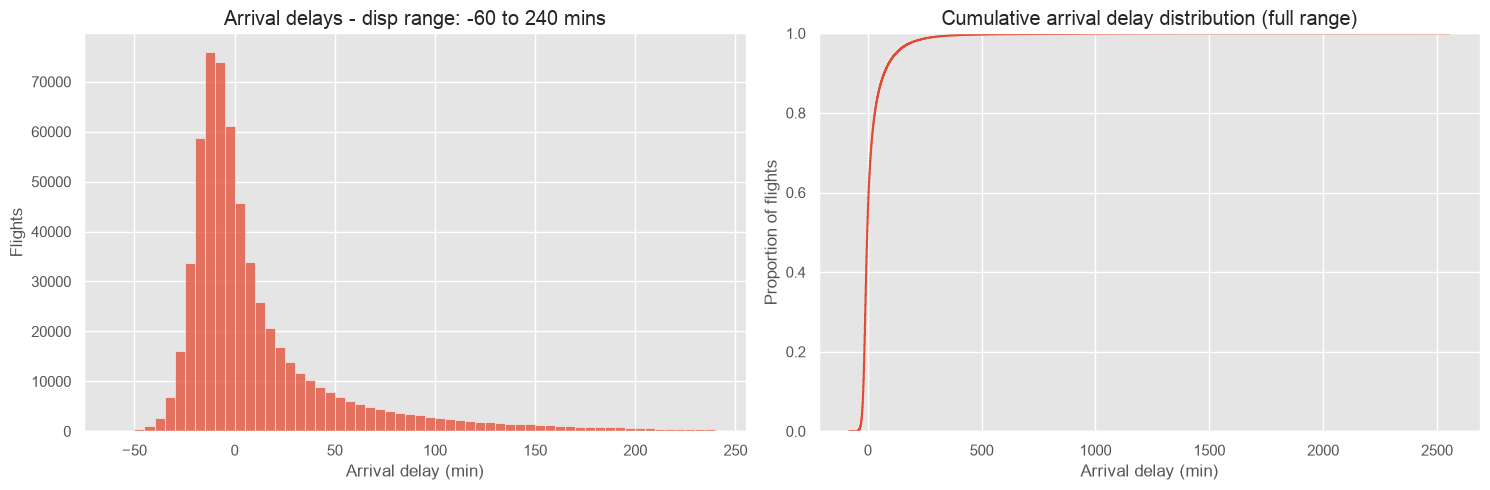

In [11]:
fig,axes = plt.subplots(1,2,figsize=(15,5))

sns.histplot(
    data = completed,
    x = "ArrDelay",
    binwidth = 5,
    binrange = (-60,240),
    ax=axes[0]
)
axes[0].set(
    title = "Arrival delays - disp range: -60 to 240 mins",
    xlabel = "Arrival delay (min)",
    ylabel = "Flights"
)
sns.ecdfplot(
    data = completed,
    x = "ArrDelay",
    ax = axes[1]
)
axes[1].set(
    title = "Cumulative arrival delay distribution (full range)",
    xlabel = "Arrival delay (min)",
    ylabel = "Proportion of flights"
)
plt.tight_layout()
plt.show()

## Airlines frequent vs severe delays

,flights,delay_rate,mean_delay_when_delayed,delay_percent
Reporting_Airline,,,,
AA,84378,0.35,94.50,34.98
AS,23012,0.31,54.11,30.64
B6,19512,0.34,94.13,33.72
DL,92245,0.25,78.93,24.84
F9,15893,0.36,91.75,36.00
G4,13855,0.30,91.46,30.10
HA,7010,0.20,51.33,20.43
MQ,26752,0.26,62.35,26.36
NK,16924,0.25,78.34,24.89


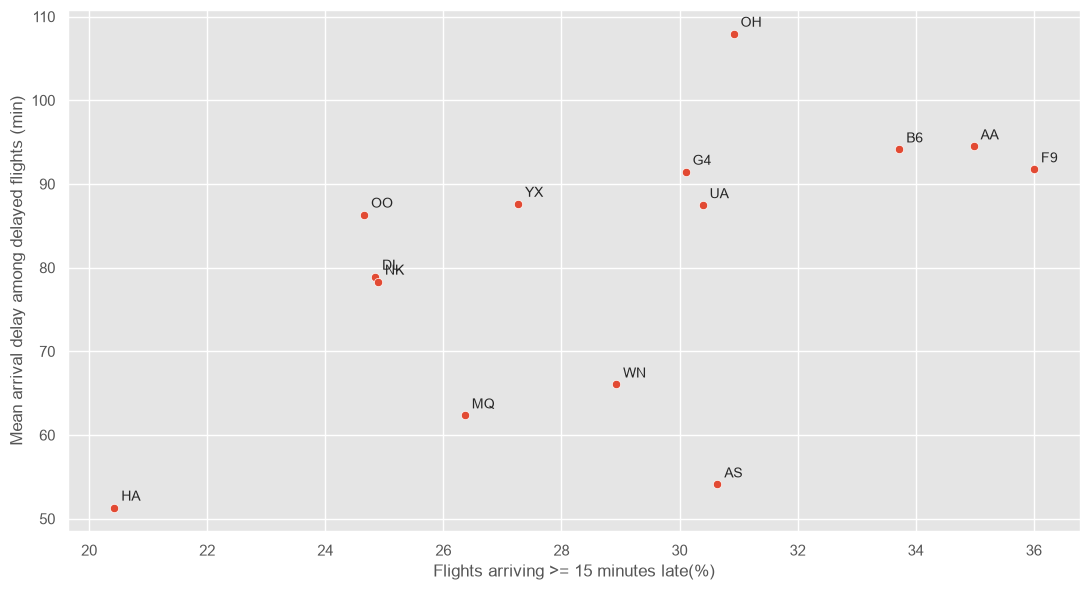

In [16]:
airline_summary = (
    completed.groupby("Reporting_Airline")
    .agg(
        flights = ("is_delayed","size"),
        delay_rate = ("is_delayed","mean")
    )
)
delayed_only = completed.loc[completed["is_delayed"]]
airline_summary["mean_delay_when_delayed"] = (
    delayed_only.groupby("Reporting_Airline")["ArrDelay"].mean()
)
airline_summary["delay_percent"] = airline_summary["delay_rate"] * 100
display(airline_summary.round(2))

fig,ax = plt.subplots(figsize=(11,6))
sns.scatterplot(
    data = airline_summary,
    x = "delay_percent",
    y = "mean_delay_when_delayed",
    ax=ax
)
for airline, row in airline_summary.iterrows():
    ax.annotate(
        airline,
        (row["delay_percent"],row["mean_delay_when_delayed"]),
        xytext=(5,5),
        textcoords = "offset points"
    )
ax.set(
    label = "Airline delay freqency and severity - July 2025",
    xlabel = "Flights arriving >= 15 minutes late(%)",
    ylabel = "Mean arrival delay among delayed flights (min)"
)
plt.tight_layout()
plt.show()